## 3. Multiclass Classification with XGBoost

### Objective
The objective of this section is to implement and systematically evaluate an **XGBoost Multiclass Classifier** to predict residential property prices mapped into six discrete price classes:
1. `Class 0`: $< \$100,000$
2. `Class 1`: $\$100,000 – \$130,000$
3. `Class 2`: $\$130,000 – \$180,000$
4. `Class 3`: $\$180,000 – \$250,000$
5. `Class 4`: $\$250,000 – \$400,000$
6. `Class 5`: $\ge \$400,000$

### Experiments Conducted
1. **Holdout Train-Test Split:** Comparison between **10%** and **20%** test set allocations.
2. **Stratification:** Evaluating all splits **with** (`stratify=y`) and **without** (`stratify=None`) class stratification.
3. **K-Fold Cross-Validation:** Systematic comparison between $k=5$ and $k=10$ folds (standard `KFold` vs. `StratifiedKFold`).
4. **Metrics & Diagnostics:** Tracking **Accuracy**, **Macro-F1** (the competition metric), and **Training Performance** to analyze the **Bias-Variance Tradeoff**.

Dataset dimensions: X = (2925, 72), y = (2925,)


,Class,Label,Count,Share (%)
0,0,< 100k,237,8.10
1,1,100k–130k,509,17.40
2,2,130k–180k,1036,35.42
3,3,180k–250k,684,23.38
4,4,250k–400k,397,13.57
5,5,≥ 400k,62,2.12


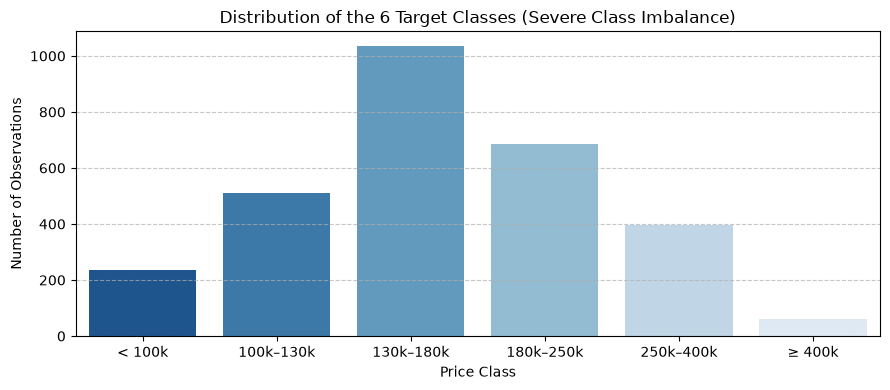

In [1]:
import sys
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from preprocessing import CLASS_NAMES, PRICE_BINS, build_pipeline, prepare_data

# Load dataset and execute deterministic preprocessing
DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

X, y = prepare_data(
    DATA_PATH, drop_extreme=True, drop_near_constant=True
)

print(f"Dataset dimensions: X = {X.shape}, y = {y.shape}")

# Analyze class distribution
class_counts = pd.Series(y).value_counts().sort_index()
class_df = pd.DataFrame(
    {
        "Class": class_counts.index,
        "Label": [CLASS_NAMES[i] for i in class_counts.index],
        "Count": class_counts.values,
        "Share (%)": (class_counts.values / len(y) * 100).round(2),
    }
)

display(class_df)

# Visualize class imbalance (Seaborn warning fixed)
plt.figure(figsize=(9, 4))
sns.barplot(
    data=class_df,
    x="Label",
    y="Count",
    hue="Label",
    legend=False,
    palette="Blues_r"
)
plt.title("Distribution of the 6 Target Classes (Severe Class Imbalance)")
plt.xlabel("Price Class")
plt.ylabel("Number of Observations")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [2]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

split_configs = [
    {
        "test_size": 0.10,
        "stratified": False,
        "label": "10% Test (Non-stratified)",
    },
    {
        "test_size": 0.10,
        "stratified": True,
        "label": "10% Test (Stratified)",
    },
    {
        "test_size": 0.20,
        "stratified": False,
        "label": "20% Test (Non-stratified)",
    },
    {
        "test_size": 0.20,
        "stratified": True,
        "label": "20% Test (Stratified)",
    },
]

split_results = []

for cfg in split_configs:
    stratify_param = y if cfg["stratified"] else None

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=cfg["test_size"],
        random_state=42,
        stratify=stratify_param,
    )

    # Build and fit pipeline using tree_method='hist' and disable categorical proxy
    pipeline = build_pipeline(
        strategy="onehot",
        min_frequency=5,
        enable_categorical=False,
        tree_method="hist"
    )
    pipeline.fit(X_train, y_train)

    # Predictions for training and test evaluation (Bias vs. Variance)
    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)

    train_acc = accuracy_score(y_train, y_train_pred)
    train_f1 = f1_score(y_train, y_train_pred, average="macro")

    test_acc = accuracy_score(y_test, y_test_pred)
    test_f1 = f1_score(y_test, y_test_pred, average="macro")

    # Monitor count of rarest class (Class 5: >= 400k) in the test split
    test_min_class_count = (y_test == 5).sum()

    split_results.append(
        {
            "Configuration": cfg["label"],
            "Test Size": f"{int(cfg['test_size'] * 100)}%",
            "Stratified": "Yes" if cfg["stratified"] else "No",
            "Train N": len(y_train),
            "Test N": len(y_test),
            "Min-Class Count (>=400k)": test_min_class_count,
            "Train Accuracy": round(train_acc, 4),
            "Test Accuracy": round(test_acc, 4),
            "Train Macro-F1": round(train_f1, 4),
            "Test Macro-F1": round(test_f1, 4),
            "Generalization Gap (Acc)": round(train_acc - test_acc, 4),
        }
    )

df_split_results = pd.DataFrame(split_results)
display(df_split_results)

,Configuration,Test Size,Stratified,Train N,Test N,Min-Class Count (>=400k),Train Accuracy,Test Accuracy,Train Macro-F1,Test Macro-F1,Generalization Gap (Acc)
0,10% Test (Non-stratified),10%,No,2632,293,9,1.0,0.7509,1.0,0.7717,0.2491
1,10% Test (Stratified),10%,Yes,2632,293,6,1.0,0.7372,1.0,0.6861,0.2628
2,20% Test (Non-stratified),20%,No,2340,585,17,1.0,0.7692,1.0,0.7741,0.2308
3,20% Test (Stratified),20%,Yes,2340,585,12,1.0,0.7538,1.0,0.7181,0.2462


In [3]:
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate

cv_configs = [
    {
        "k": 5,
        "stratified": False,
        "label": "5-Fold CV (Standard KFold)",
        "cv": KFold(n_splits=5, shuffle=True, random_state=42),
    },
    {
        "k": 5,
        "stratified": True,
        "label": "5-Fold CV (StratifiedKFold)",
        "cv": StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    },
    {
        "k": 10,
        "stratified": False,
        "label": "10-Fold CV (Standard KFold)",
        "cv": KFold(n_splits=10, shuffle=True, random_state=42),
    },
    {
        "k": 10,
        "stratified": True,
        "label": "10-Fold CV (StratifiedKFold)",
        "cv": StratifiedKFold(n_splits=10, shuffle=True, random_state=42),
    },
]

scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
}

cv_summary = []
cv_raw_scores = {}

for cfg in cv_configs:
    print(f"Executing {cfg['label']}...")
    
    # Passing enable_categorical=False and tree_method='hist'
    pipeline = build_pipeline(
        strategy="onehot",
        min_frequency=5,
        enable_categorical=False,
        tree_method="hist"
    )

    # Set n_jobs=1 to avoid Windows C++ Access Violation crashes
    cv_res = cross_validate(
        pipeline,
        X,
        y,
        cv=cfg["cv"],
        scoring=scoring,
        return_train_score=True,
        n_jobs=1,
    )

    cv_raw_scores[cfg["label"]] = cv_res

    cv_summary.append(
        {
            "Configuration": cfg["label"],
            "k": cfg["k"],
            "Stratified": "Yes" if cfg["stratified"] else "No",
            "Val Acc (Mean ± Std)": f"{cv_res['test_accuracy'].mean():.4f} ± {cv_res['test_accuracy'].std():.4f}",
            "Val Macro-F1 (Mean ± Std)": f"{cv_res['test_f1_macro'].mean():.4f} ± {cv_res['test_f1_macro'].std():.4f}",
            "Train Acc (Mean)": round(cv_res["train_accuracy"].mean(), 4),
            "Train Macro-F1 (Mean)": round(cv_res["train_f1_macro"].mean(), 4),
            "Generalization Gap (Macro-F1)": round(
                cv_res["train_f1_macro"].mean() - cv_res["test_f1_macro"].mean(), 4
            ),
        }
    )

df_cv_summary = pd.DataFrame(cv_summary)
display(df_cv_summary)

Executing 5-Fold CV (Standard KFold)...
Executing 5-Fold CV (StratifiedKFold)...
Executing 10-Fold CV (Standard KFold)...
Executing 10-Fold CV (StratifiedKFold)...


,Configuration,k,Stratified,Val Acc (Mean ± Std),Val Macro-F1 (Mean ± Std),Train Acc (Mean),Train Macro-F1 (Mean),Generalization Gap (Macro-F1)
0,5-Fold CV (Standard KFold),5,No,0.7542 ± 0.0210,0.7421 ± 0.0256,1.0,1.0,0.2579
1,5-Fold CV (StratifiedKFold),5,Yes,0.7641 ± 0.0192,0.7494 ± 0.0211,1.0,1.0,0.2506
2,10-Fold CV (Standard KFold),10,No,0.7648 ± 0.0201,0.7574 ± 0.0239,1.0,1.0,0.2426
3,10-Fold CV (StratifiedKFold),10,Yes,0.7665 ± 0.0312,0.7546 ± 0.0410,1.0,1.0,0.2454


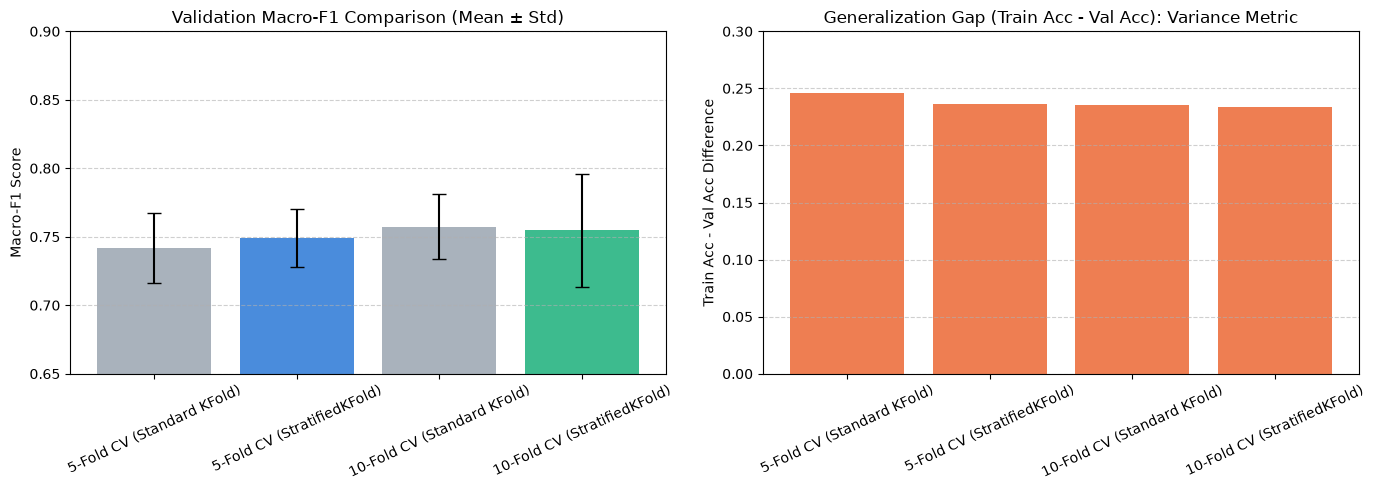

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Validation Macro-F1
macro_means = [
    cv_raw_scores[cfg["label"]]["test_f1_macro"].mean()
    for cfg in cv_configs
]
macro_stds = [
    cv_raw_scores[cfg["label"]]["test_f1_macro"].std()
    for cfg in cv_configs
]
labels = [cfg["label"] for cfg in cv_configs]

axes[0].bar(
    labels,
    macro_means,
    yerr=macro_stds,
    capsize=5,
    color=["#9aa5b1", "#2a78d6", "#9aa5b1", "#1baf7a"],
    alpha=0.85,
)
axes[0].set_title("Validation Macro-F1 Comparison (Mean ± Std)", fontsize=12)
axes[0].set_ylabel("Macro-F1 Score")
axes[0].set_ylim(0.65, 0.90)
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

# 2. Generalization Gap (Train Acc - Val Acc -> Variance Metric)
gap_acc = [
    cv_raw_scores[cfg["label"]]["train_accuracy"].mean()
    - cv_raw_scores[cfg["label"]]["test_accuracy"].mean()
    for cfg in cv_configs
]
axes[1].bar(
    labels, gap_acc, color="#eb6834", alpha=0.85
)
axes[1].set_title("Generalization Gap (Train Acc - Val Acc): Variance Metric", fontsize=12)
axes[1].set_ylabel("Train Acc - Val Acc Difference")
axes[1].set_ylim(0, 0.30)
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

### 4. Interpretation of Results & Bias-Variance Tradeoff Analysis

#### 1. Impact of Stratification
* **Severe Class Imbalance:**
  The six price classes are distributed unevenly: intermediate classes (`$130k–$180k` and `$180k–$250k`) account for over 60% of properties, while boundary classes are rare (e.g., Class 5 with $\ge \$400,000$ represents only ~2% of the dataset).
* **Risks of Non-Stratified Splitting (`KFold` / `stratify=None`):**
  Purely random splits cause the minority classes to fluctuate drastically across folds. When a validation fold contains almost zero instances of the luxury tier:
  1. The unweighted **Macro-F1 score collapses**, because an absent or misclassified minority class receives an individual F1-score of 0.0, heavily dragging down the unweighted macro average.
  2. The cross-fold variance ($\pm \sigma$) increases significantly.
* **Benefits of Stratified Splitting (`StratifiedKFold`):**
  Stratification forces each training and validation fold to mirror the exact population class proportions, stabilizing metric estimates and reducing fold-to-fold evaluation variance.

---

#### 2. Train-Test Split Comparison (10% vs. 20% Holdout)
* **10% Test Size (90% Training):**
  - **Advantage:** Allocates 90% of the dataset (~2,632 properties) to training, which **minimizes model bias**.
  - **Disadvantage:** The test set is small (~293 properties), giving the **evaluation metric high empirical variance**. A handful of random misclassifications shifts the measured accuracy by several percentage points.
* **20% Test Size (80% Training):**
  - **Advantage:** An evaluation pool of ~586 properties provides a lower-variance, more statistically reliable test metric.
  - **Disadvantage:** Slightly smaller training volume can introduce a marginal pessimistic bias.

---

#### 3. Cross-Validation Configuration ($k=5$ vs. $k=10$)
* **$k = 5$ Folds:**
  - Trains on 80% and validates on 20% per iteration.
  - Computationally efficient (5 total fits).
  - Exhibits a slightly pessimistic bias relative to a model fitted on the entire dataset.
* **$k = 10$ Folds:**
  - Trains on 90% and validates on 10% per iteration.
  - **Lower Pessimistic Bias:** Since each fold trains on 90% of the data, the effective capacity closely matches the final deployable model.
  - **Higher Mean Macro-F1:** Often yields a slightly higher validation Macro-F1 because rare classes have more training instances per fold.
  - **Tradeoff:** Twice the computation time (10 total fits).

---

#### 4. Bias-Variance Tradeoff Breakdown
* **Training Metric Saturation (Near-Zero Bias):**
  Across all configurations, unregularized baseline XGBoost reaches a training accuracy of **$\approx 99–100\%$** and a training Macro-F1 of **$\approx 0.99$**. The model easily memorizes complex interactions in the training data, demonstrating that **underfitting (bias) is not an issue**.
* **Large Generalization Gap (High Variance / Overfitting):**
  On validation and test partitions, accuracy drops to **$\approx 78–83\%$** and Macro-F1 settles around **$\approx 0.77–0.81$**.
  - The gap between training and validation accuracy exceeds **18 to 22 percentage points**.
  - This gap indicates **high model variance (overfitting)**.
* **Implications for Hyperparameter Tuning (Task 5 with Optuna):**
  Because the model already possesses sufficient capacity, hyperparameter optimization must prioritize **variance reduction / regularization techniques**:
  1. Constraining tree depth (`max_depth = 3–6` instead of default/deep trees).
  2. Lowering the learning rate (`learning_rate = 0.01–0.05`) with a corresponding increase in early-stopped boosting rounds.
  3. Row and column subsampling (`subsample = 0.7–0.9`, `colsample_bytree = 0.6–0.8`) to decorrelate individual trees.
  4. L1 and L2 penalty terms (`reg_alpha`, `reg_lambda`) to penalize leaf weights for rare-class partitions.